In [ ]:
#Imports

import torch
from torch import nn, save, load
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
import timm

import matplotlib.pyplot as plt # For data viz
import pandas as pd
import numpy as np
import sys
from tqdm.notebook import tqdm

In [3]:
#Pytorch Dataset and Dataloader
class PlayingCardDataset(Dataset):
    def __init__(self, data_dir, transform=None):
        self.data = ImageFolder(data_dir, transform=transform)
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        return self.data[idx]
    
    @property
    def classes(self):
        return self.data.classes


In [4]:
#dataset paths
dataset = PlayingCardDataset(data_dir = 'Card Image Dataset-Classification/train')


In [5]:
len(dataset)

7624

In [6]:
dataset[5]

(<PIL.Image.Image image mode=RGB size=224x224>, 0)

10


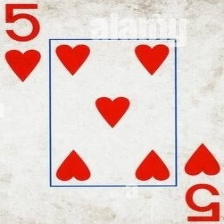

In [7]:
image, label = dataset[1500]
print(label)
image

In [8]:
#Get a dictionary associating target values with folder names
data_dir = 'Card Image Dataset-Classification/train'
target_to_class = {v: k for k, v in ImageFolder(data_dir).class_to_idx.items()}
print(target_to_class)

{0: 'ace of clubs', 1: 'ace of diamonds', 2: 'ace of hearts', 3: 'ace of spades', 4: 'eight of clubs', 5: 'eight of diamonds', 6: 'eight of hearts', 7: 'eight of spades', 8: 'five of clubs', 9: 'five of diamonds', 10: 'five of hearts', 11: 'five of spades', 12: 'four of clubs', 13: 'four of diamonds', 14: 'four of hearts', 15: 'four of spades', 16: 'jack of clubs', 17: 'jack of diamonds', 18: 'jack of hearts', 19: 'jack of spades', 20: 'joker', 21: 'king of clubs', 22: 'king of diamonds', 23: 'king of hearts', 24: 'king of spades', 25: 'nine of clubs', 26: 'nine of diamonds', 27: 'nine of hearts', 28: 'nine of spades', 29: 'queen of clubs', 30: 'queen of diamonds', 31: 'queen of hearts', 32: 'queen of spades', 33: 'seven of clubs', 34: 'seven of diamonds', 35: 'seven of hearts', 36: 'seven of spades', 37: 'six of clubs', 38: 'six of diamonds', 39: 'six of hearts', 40: 'six of spades', 41: 'ten of clubs', 42: 'ten of diamonds', 43: 'ten of hearts', 44: 'ten of spades', 45: 'three of clu

In [9]:
transform = transforms.Compose([
    transforms.Resize((128, 128)), 
    transforms.ToTensor(),
])

data_dir = 'Card Image Dataset-Classification/train'
dataset = PlayingCardDataset(data_dir, transform)

In [10]:
image, label = dataset[100]
image.shape

torch.Size([3, 128, 128])

In [11]:
# iterate over dataset
for image, label in dataset:
    break

In [12]:
label

0

In [13]:
# DataLoader Batching our dataset
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)


In [14]:
for images, labels in dataloader:
    break

In [15]:
images.shape, labels.shape

(torch.Size([32, 3, 128, 128]), torch.Size([32]))

In [16]:
labels

tensor([36, 18,  5,  0, 37, 32, 26,  3, 34, 51, 41, 12, 30, 46, 39, 47, 12, 19,
        37, 44, 16, 51, 26, 26, 27, 22,  5, 50,  4, 14, 14, 38])

In [17]:
# step 2: creating pytorch model
class SimpleCardClassifier(nn.Module):
    def __init__(self, num_classes=53):
        super(SimpleCardClassifier, self).__init__()
        # Where we define all the parts of the model
        self.base_model = timm.create_model('efficientnet_b0', pretrained=True)
        self.features = nn.Sequential(*list(self.base_model.children())[:-1]) # Remove last layer (extra layer we don't need)

        enet_out_size = 1280
        #make a classifier
        self.classifier = nn.Linear(enet_out_size, num_classes)


    def forward(self, x):
        # Connect these parts and return the output
        x = self.features(x)
        output = self.classifier(x)
        return output


In [18]:
model = SimpleCardClassifier(num_classes = 53)
print(str(model) [:500]) #print the model architecture

'(MaxRetryError('HTTPSConnectionPool(host=\'huggingface.co\', port=443): Max retries exceeded with url: /timm/efficientnet_b0.ra_in1k/resolve/main/model.safetensors (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x000002CE6D3A86E0>: Failed to resolve \'huggingface.co\' ([Errno 11001] getaddrinfo failed)"))'), '(Request ID: d4d26d5b-bd99-4e82-88c6-8a08656998dc)')' thrown while requesting HEAD https://huggingface.co/timm/efficientnet_b0.ra_in1k/resolve/main/model.safetensors
Retrying in 1s [Retry 1/5].
'(MaxRetryError('HTTPSConnectionPool(host=\'huggingface.co\', port=443): Max retries exceeded with url: /timm/efficientnet_b0.ra_in1k/resolve/main/model.safetensors (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x000002CE6D3A0F50>: Failed to resolve \'huggingface.co\' ([Errno 11001] getaddrinfo failed)"))'), '(Request ID: efdcc108-28d2-47a1-be91-9b11c3caad92)')' thrown while requesting HEAD https://huggingface.co/timm/efficient

SimpleCardClassifier(
  (base_model): EfficientNet(
    (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=Fa


In [19]:
model(images)

tensor([[-0.1150,  0.3449,  0.1142,  ..., -0.0174, -0.0552,  0.4460],
        [-0.1139,  0.5919, -0.4156,  ..., -0.5216, -0.0519, -0.4133],
        [ 0.1514,  0.4701, -0.2146,  ..., -0.4285,  0.7809,  0.2269],
        ...,
        [-0.3639,  0.1059, -0.2805,  ...,  0.5731, -0.1088,  0.0728],
        [ 0.4526,  0.4250, -0.4060,  ...,  0.5197,  0.3750,  0.1492],
        [ 0.0127,  0.1524, -0.1788,  ..., -0.1399,  0.3742,  0.1712]],
       grad_fn=<AddmmBackward0>)

In [20]:
example_output = model(images)
example_output.shape #[batch_size, num_classes]

torch.Size([32, 53])

In [ ]:
# Step 3: creating the training loop

In [23]:
#loss function
criterion = nn.CrossEntropyLoss() # common loss function for multi-class classification

#optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001) # simple and effective optimizer


In [22]:
criterion(example_output, labels) # checking if the loss function works with the input data that we have

tensor(4.1082, grad_fn=<NllLossBackward0>)

In [24]:
# Setup Datasets

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

train_folder = 'Card Image Dataset-Classification/train'
test_folder = 'Card Image Dataset-Classification/test'
validation_folder = 'Card Image Dataset-Classification/valid'

train_dataset = PlayingCardDataset(train_folder, transform=transform)
test_dataset = PlayingCardDataset(test_folder, transform=transform)
validation_dataset = PlayingCardDataset(validation_folder, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
validation_loader = DataLoader(validation_dataset, batch_size=32, shuffle=False)

In [28]:
# finally creating the damn training loob

num_epochs = 2
train_losses, validation_losses = [], []

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

model = SimpleCardClassifier(num_classes =53)
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(num_epochs):
    # set the model to train
    model.train()
    running_loss = 0.0
    for images, labels in tqdm(train_loader, desc='Training loop'):

        # move the inputs and labels to the device
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad() # zero the gradients
        outputs = model(images) # forward pass
        loss = criterion(outputs, labels) # calculate the loss
        loss.backward() # backpropagation to update the model weight 
        optimizer.step() # update the weights
        running_loss += loss.item() * images.size(0) # accumulate the loss
        # everytime this  inner loob is completed 1 epoch is completed


        # now we want to save the training loss
        train_loss = running_loss / len(train_loader.dataset)
        train_losses.append(train_loss)

        # validation loop or phase of the process
        model.eval() # set the model to evaluation mode
        running_loss = 0.0
        with torch.no_grad():
            for images, labels in tqdm(validation_loader, desc='Validation_loop'):
                outputs = model(images)
                loss = criterion(outputs, labels)
                running_loss += loss.item() * images.size(0)
            validation_loss = running_loss / len(validation_loader.dataset)
            validation_losses.append(validation_loss)

            # printing the epoch State / information
            print(f"Epoch {epoch+1}/{num_epochs} - Train Loss: {train_losses}, validation Loss: {validation_losses}")

Training loop:   0%|          | 0/239 [00:00<?, ?it/s]

Validation_loop:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 1/2 - Train Loss: [0.01685903455127824], validation Loss: [4.00122053308307]


Validation_loop:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 1/2 - Train Loss: [0.01685903455127824, 0.15584786075234788], validation Loss: [4.00122053308307, 3.9512049234138344]


...

Epoch 2/2 - Train Loss: [0.01685903455127824, 0.15584786075234788, 0.15407201091114897, 0.15415499727598392, 0.1551597079600267, 0.15700078323280198, 0.15821871264658846, 0.1729906228569347, 0.17712861230716126, 0.15420237618253213, 0.18294401940618957, 0.16495737380270942, 0.7738779038972644, 0.15802936370075063, 0.16215463894236626, 0.17364490842143737, 0.2543882069032315, 0.19866301136527206, 0.23450523214600394, 0.26147763926735207, 0.1810668142745027, 0.22527498300778528, 0.15476630448294337, 0.15457407537562398, 0.15583499603106368, 0.16449879580504748, 0.1586994803339587, 0.15832826635895095, 0.15742061073732527, 0.1559218109467097, 0.15813533553671863, 0.15409338868302289, 0.16982067137925347, 0.15722420164320428, 0.15582693423704486, 0.1820967504510349, 0.15857065177414126, 0.1563035472680239, 0.15937569996992915, 0.15725401953910356, 0.22753041144558164, 1.711172990508745, 0.15591763808994955, 0.172106880206001, 0.15877202625414757, 0.15692698692850152, 0.15479582892134708, 0

Validation_loop:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 2/2 - Train Loss: [0.01685903455127824, 0.15584786075234788, 0.15407201091114897, 0.15415499727598392, 0.1551597079600267, 0.15700078323280198, 0.15821871264658846, 0.1729906228569347, 0.17712861230716126, 0.15420237618253213, 0.18294401940618957, 0.16495737380270942, 0.7738779038972644, 0.15802936370075063, 0.16215463894236626, 0.17364490842143737, 0.2543882069032315, 0.19866301136527206, 0.23450523214600394, 0.26147763926735207, 0.1810668142745027, 0.22527498300778528, 0.15476630448294337, 0.15457407537562398, 0.15583499603106368, 0.16449879580504748, 0.1586994803339587, 0.15832826635895095, 0.15742061073732527, 0.1559218109467097, 0.15813533553671863, 0.15409338868302289, 0.16982067137925347, 0.15722420164320428, 0.15582693423704486, 0.1820967504510349, 0.15857065177414126, 0.1563035472680239, 0.15937569996992915, 0.15725401953910356, 0.22753041144558164, 1.711172990508745, 0.15591763808994955, 0.172106880206001, 0.15877202625414757, 0.15692698692850152, 0.15479582892134708, 0

Validation_loop:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 2/2 - Train Loss: [0.01685903455127824, 0.15584786075234788, 0.15407201091114897, 0.15415499727598392, 0.1551597079600267, 0.15700078323280198, 0.15821871264658846, 0.1729906228569347, 0.17712861230716126, 0.15420237618253213, 0.18294401940618957, 0.16495737380270942, 0.7738779038972644, 0.15802936370075063, 0.16215463894236626, 0.17364490842143737, 0.2543882069032315, 0.19866301136527206, 0.23450523214600394, 0.26147763926735207, 0.1810668142745027, 0.22527498300778528, 0.15476630448294337, 0.15457407537562398, 0.15583499603106368, 0.16449879580504748, 0.1586994803339587, 0.15832826635895095, 0.15742061073732527, 0.1559218109467097, 0.15813533553671863, 0.15409338868302289, 0.16982067137925347, 0.15722420164320428, 0.15582693423704486, 0.1820967504510349, 0.15857065177414126, 0.1563035472680239, 0.15937569996992915, 0.15725401953910356, 0.22753041144558164, 1.711172990508745, 0.15591763808994955, 0.172106880206001, 0.15877202625414757, 0.15692698692850152, 0.15479582892134708, 0

In [ ]:
# Save the trained model weights
torch.save(model.state_dict(), 'simple_card_classifier.pt')

In [ ]:
# Recreate the model architecture
model = SimpleCardClassifier(num_classes=53)
model.load_state_dict(torch.load('simple_card_classifier.pt'))
model.to(device)
model.eval()  # Set to evaluation mode if you're doing inference

In [25]:
# visualize losses

plt.plot(train_losses, label='Training loss')
plt.plot(validation_losses, label='Validation loss')
plt.legend()
plt.title("Loss over epochs")
plt.show()


NameError: name 'train_losses' is not defined

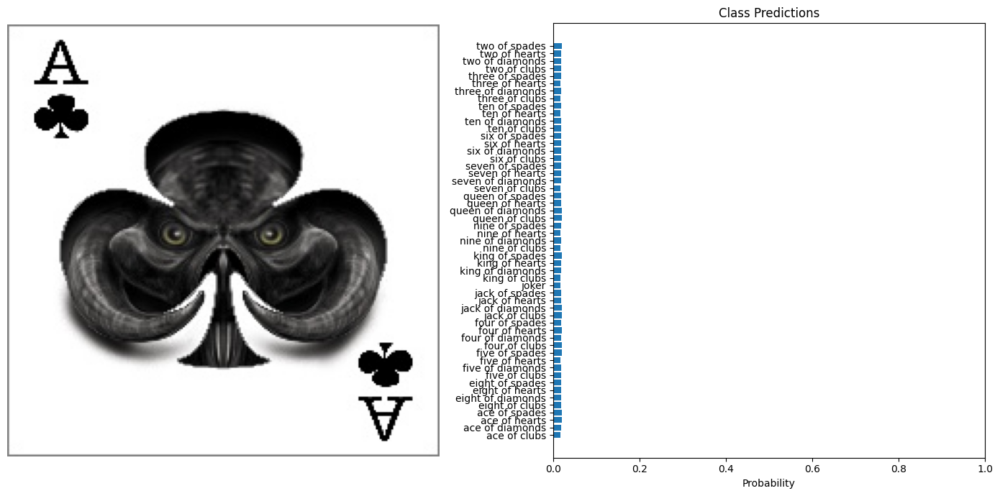

In [ ]:
import torch
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Load and preprocess the image
def preprocess_image(image_path, transform):
    image = Image.open(image_path).convert("RGB")
    return image, transform(image).unsqueeze(0)

# Recreate the model architecture
model = SimpleCardClassifier(num_classes=53)
model.load_state_dict(torch.load('simple_card_classifier.pt'))
model.to(device)

# Predict using the model
def predict(model, image_tensor, device):
    model.eval()
    with torch.no_grad():
        image_tensor = image_tensor.to(device)
        outputs = model(image_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
    return probabilities.cpu().numpy().flatten()

# Visualization
def visualize_predictions(original_image, probabilities, class_names):
    fig, axarr = plt.subplots(1, 2, figsize=(14, 7))
    
    # Display image
    axarr[0].imshow(original_image)
    axarr[0].axis("off")
    
    # Display predictions
    axarr[1].barh(class_names, probabilities)
    axarr[1].set_xlabel("Probability")
    axarr[1].set_title("Class Predictions")
    axarr[1].set_xlim(0, 1)

    plt.tight_layout()
    plt.show()

# Example usage
test_image = 'Card Image Dataset-Classification/test/ace of clubs/1.jpg'
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

original_image, image_tensor = preprocess_image(test_image, transform)
probabilities = predict(model, image_tensor, device)

# Assuming dataset.classes gives the class names
class_names = dataset.classes 
visualize_predictions(original_image, probabilities, class_names)

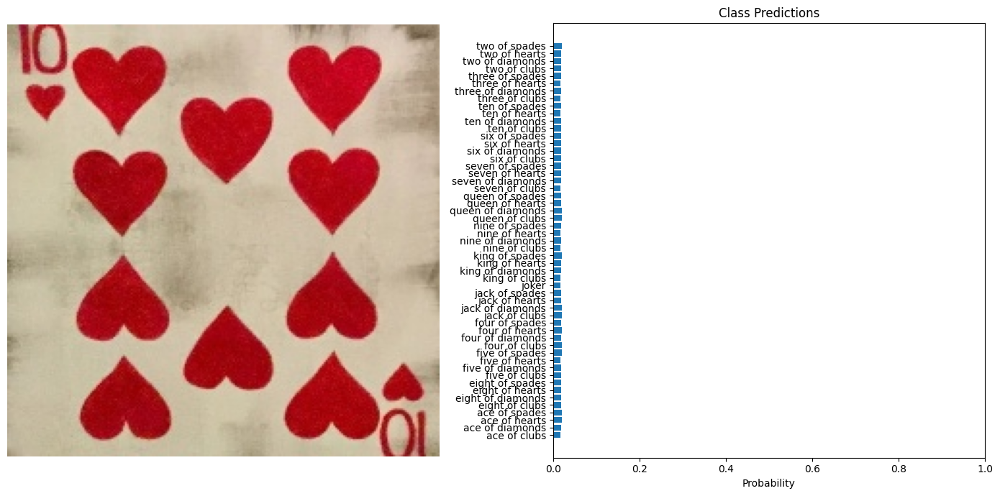

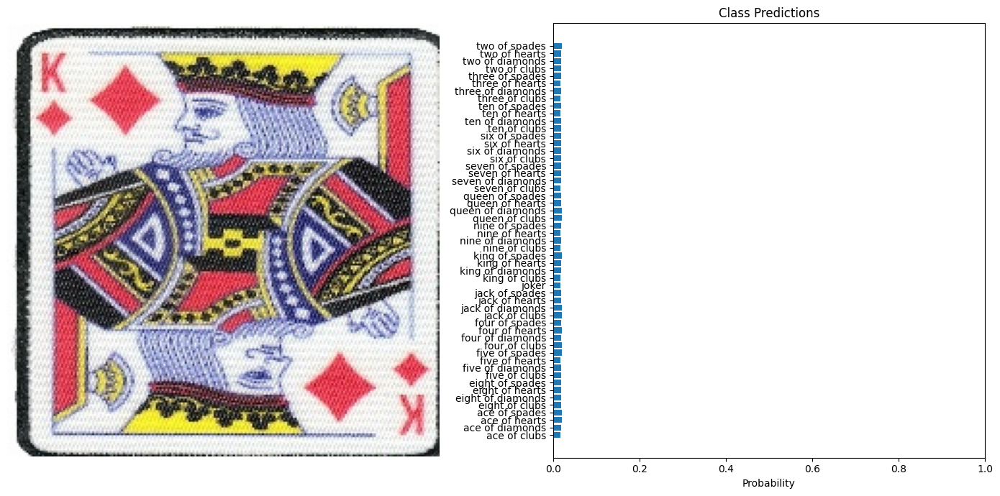

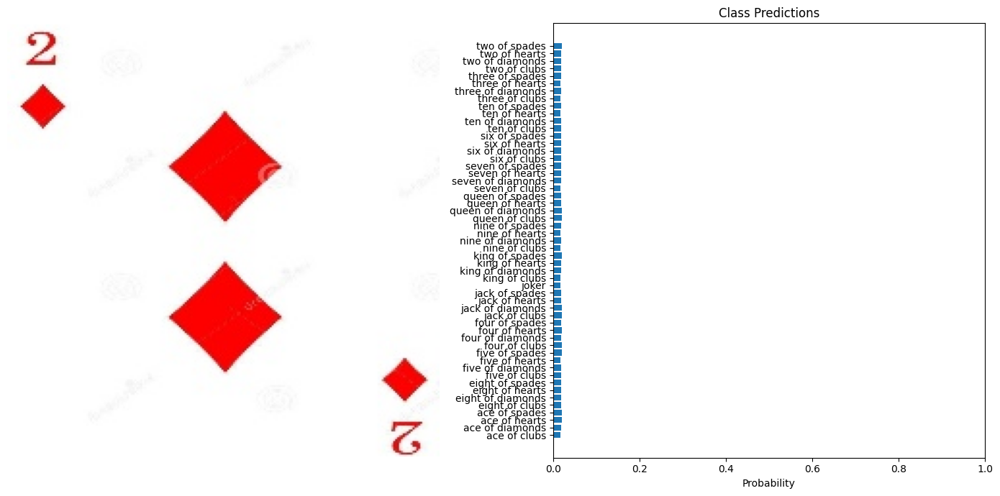

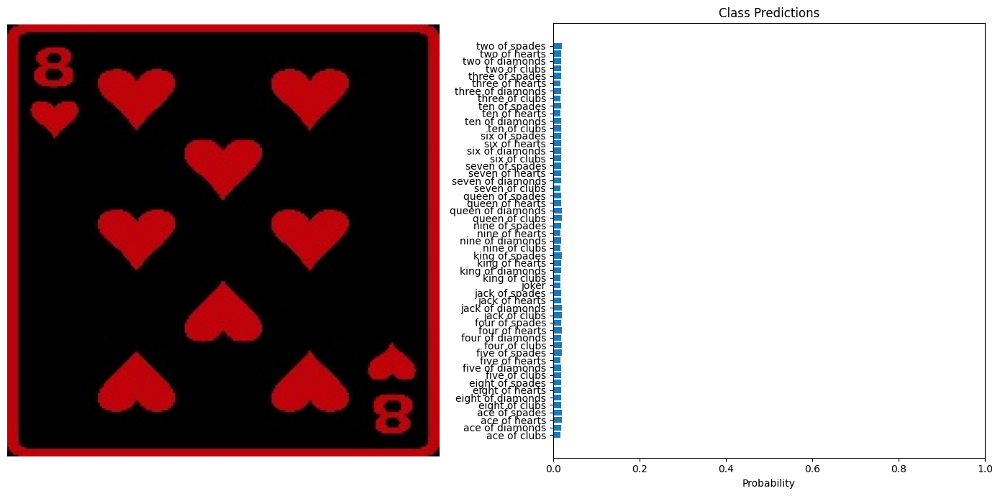

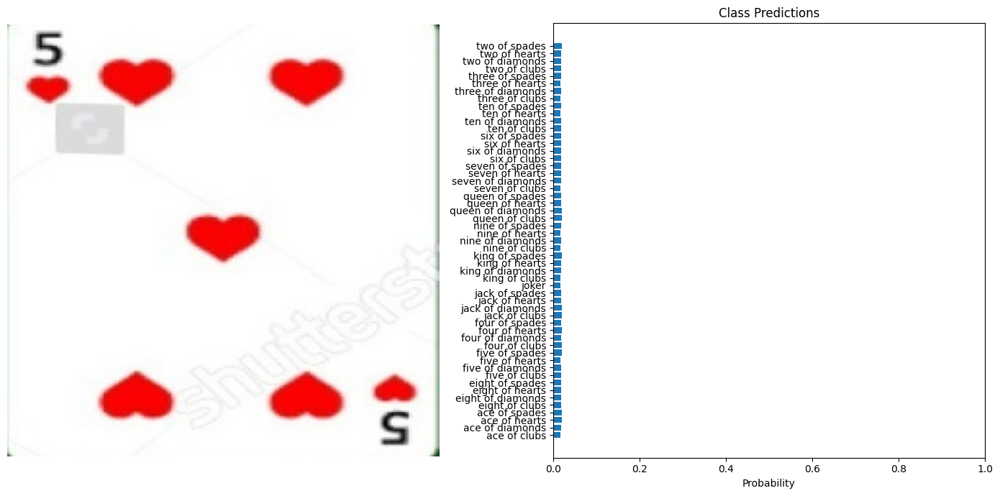

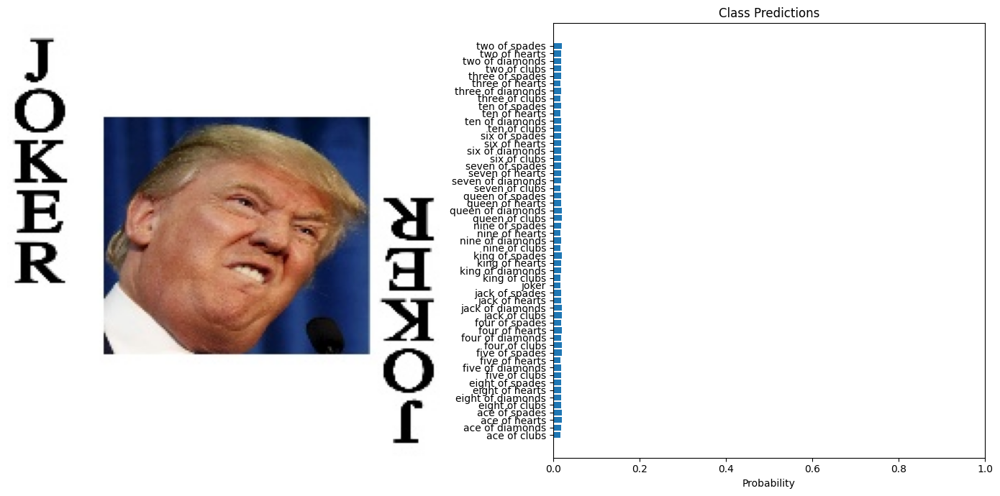

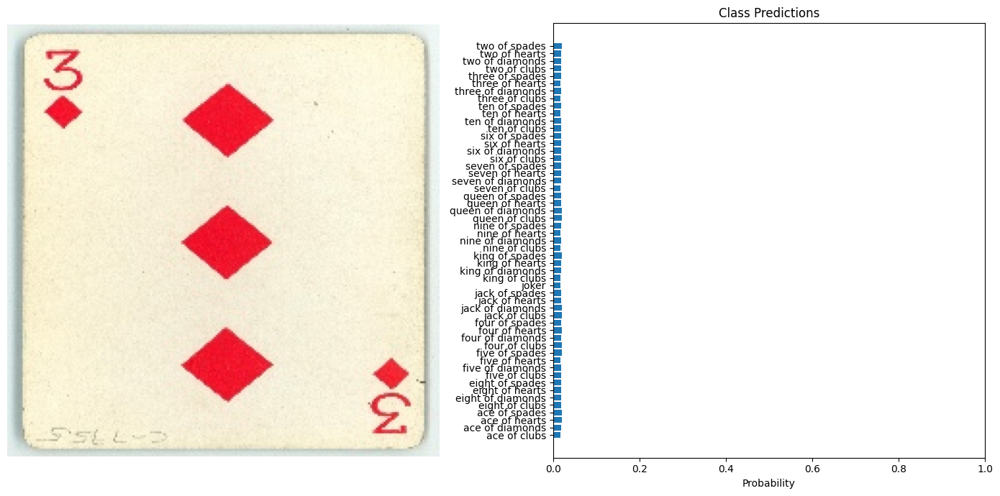

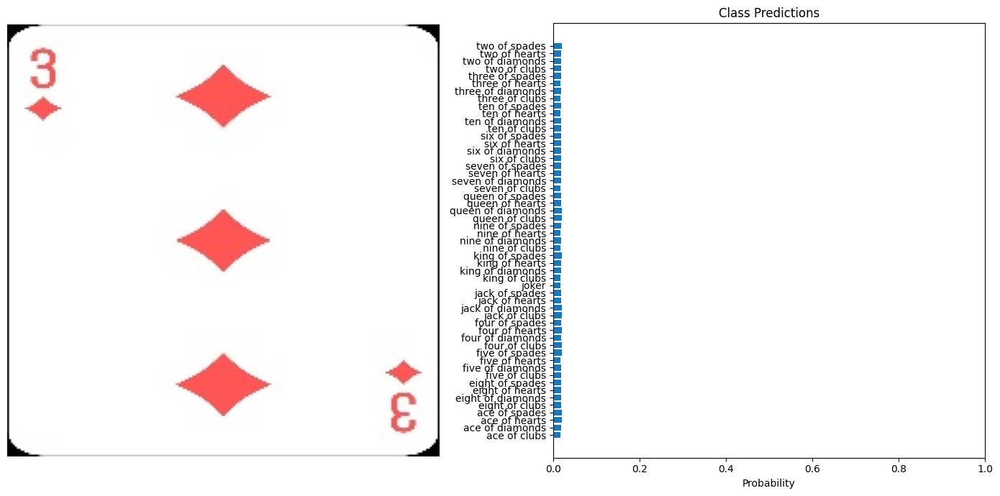

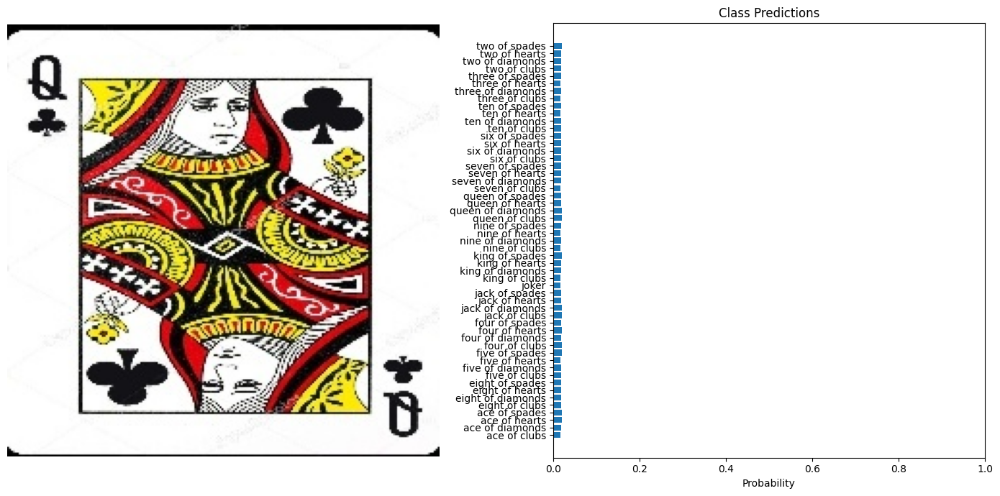

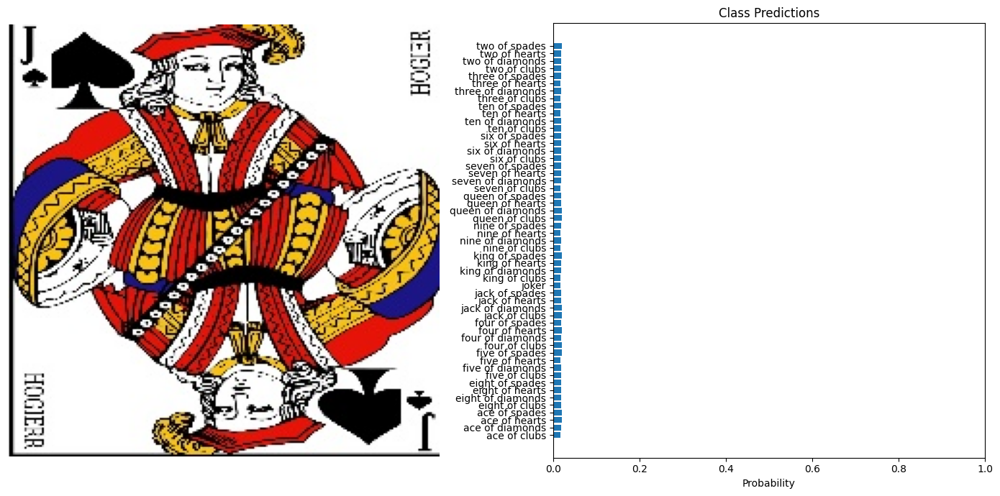

In [30]:
from glob import glob
test_images = glob('Card Image Dataset-Classification/test/*/*')
test_examples = np.random.choice(test_images, 10)

for example in test_examples:
    original_image, image_tensor = preprocess_image(example, transform)
    probabilities = predict(model, image_tensor, device)

    # Assuming dataset.classes gives the class names
    class_names = dataset.classes 
    visualize_predictions(original_image, probabilities, class_names)